In [2]:
import os
import chromadb
import pandas as pd

from dotenv import load_dotenv
from pypdf import PdfReader

from openrouter import OpenRouter

### configure environment 

In [3]:
load_dotenv()

OPENROUTER_API_KEY = os.getenv("OPENROUTER_API_KEY")
OPENROUTER_MODEL = os.getenv("OPENROUTER_MODEL")

if not OPENROUTER_API_KEY:
    raise ValueError("OPENROUTER_API_KEY not found!")

if not OPENROUTER_MODEL:
    raise ValueError("OPENROUTER_MODEL not found!")

llm = OpenRouter(
    api_key=OPENROUTER_API_KEY
)

print("Environment configured successfully!")


Environment configured successfully!


### initialize the Chromadb

In [4]:
chroma_client = chromadb.PersistentClient(
    path="./advanced_rag_db"
)

collection = chroma_client.get_or_create_collection(
    name="advanced_rag_documents"
)

print("Collection:", collection.name)
print("Existing documents:", collection.count())

Collection: advanced_rag_documents
Existing documents: 0


### Make document chunk

In [19]:
def slpit_into_chunk( content , chunk_size=800, overlap=100):
    return content
    chunks= []

    start=0
    while start < len(content):
        end = start + chunk_size
        print(content[start:end])
        chunk.append(content[start:end])
        start += chunk_size

        start += chunk_size - overlap
    
    return chunks


In [18]:
with open("../documents.txt", "r", encoding="utf-8") as file:
    content = file.read()

chunks = slpit_into_chunk(content)
chunks[0]

'#'

In [7]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

In [8]:
from utils.config import (
    create_embeddings,
    store_embeded_cunks,
    collection
)

print("Embedding and storage functions imported successfully!")

Embedding and storage functions imported successfully!


### Create embedding
---

In [10]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

In [12]:
with open("../documents.txt", "r", encoding="utf-8") as file:
    content = file.read()

content

'# Developer Profile and Personal Knowledge Base\n\n## 1. Personal and Professional Overview\n\nThe developer uses the professional identity MAR Miju and the developer username `marmiju`. He is a web developer based in Bangladesh who is interested in building useful, reliable, and production-quality software. His professional focus includes full-stack web development, backend engineering, e-commerce solutions, AI engineering, and automation.\n\nHe prefers working on projects that solve real business problems rather than building applications only for demonstration purposes. His long-term goal is to develop professional engineering skills and work on international projects, SaaS platforms, business applications, and systems that can serve real users at scale.\n\nHe offers freelance development services to agencies and direct clients. He is particularly interested in delivering complete solutions, from design implementation and backend development to deployment and post-launch support.\n

In [13]:
embeded_chunks = create_embeddings(content)

Embedding started...


KeyboardInterrupt: 

### Store Embedding in Vector Database(chromadb)

In [13]:
store_embeded_cunks(embeded_cunks=embeded_chunks, chunks=chunks)
print('stored embeded chunk successfuly')

NameError: name 'embeded_chunks' is not defined

### verify Chromadb Storage

In [ ]:
print("Total stored documents:", collection.count())

# Inspect stored records
stored_data = collection.get(
    limit=3,
    include=["documents", "embeddings"]
)

for i in range(len(stored_data["ids"])):
    print(f"\nID: {stored_data['ids'][i]}")
    print(f"Document: {stored_data['documents'][i][:150]}")
    print(f"Vector dimensions: {len(stored_data['embeddings'][i])}")

Total stored documents: 38

ID: chunk-0
Document: # Developer Profile and Personal Knowledge Base

## 1. Personal and Professional Overview

The developer uses the professional identity MAR Miju and t
Vector dimensions: 384

ID: chunk-1
Document: ommerce solutions, AI engineering, and automation.

He prefers working on projects that solve real business problems rather than building applications
Vector dimensions: 384

ID: chunk-2
Document: ce development services to agencies and direct clients. He is particularly interested in delivering complete solutions, from design implementation and
Vector dimensions: 384


### rewite prompt


In [1]:
QUERY_REWRITE_PROMPT = """
You are an expert Query Rewriting Engine for a personal software engineering and AI knowledge-base RAG system.

Your task is to rewrite the user's original question into ONE optimized search query for retrieving relevant information from the knowledge base.

## Knowledge Base Description

The knowledge base contains information about a software engineer and AI enthusiast, including:

- Professional identity and background
- Education and experience
- Programming languages and technical skills
- Backend and frontend development
- Software engineering principles
- Personal and professional projects
- AI engineering and RAG learning
- Embeddings and vector databases
- Development tools and environment
- Software architecture interests
- Freelancing and business activities
- Career goals and learning preferences

Use this description only to understand the knowledge domain. Do not assume that every question concerns the same topic.

## Query Rewriting Process

Analyze the original question using these steps:

1. Identify the user's actual information need.
2. Identify important entities, technologies, project names, concepts, and relationships.
3. Resolve contextual references only when supported by the available context.
4. Identify whether the question concerns past experience, current activities, future goals, or personal preferences.
5. Convert informal or ambiguous wording into clear technical terminology when appropriate.
6. Preserve the original question's scope and intent.
7. Include relevant keywords that may appear in the knowledge-base document.
8. Remove unnecessary conversational wording.
9. Avoid adding unrelated technologies or concepts.
10. Preserve important constraints such as dates, project names, and specific comparisons.

## Important Restrictions

- Never answer the user's question.
- Never invent information.
- Never assume that the user has experience with every technology mentioned in the knowledge base.
- Never convert a learning interest into professional experience.
- Never convert a future goal into an existing achievement.
- Do not generate multiple search queries.
- Do not unnecessarily expand a simple question.
- If the original question is already suitable for retrieval, return it unchanged.

## Input

Original User Question:
{query}

## Output

Return ONLY the optimized search query.

No explanations, labels, markdown, or additional text.
"""

### rewrite function

In [147]:
def rewrite_query(query: str) -> str:

    prompt = QUERY_REWRITE_PROMPT.format(query=query)

    response = client.chat.send(
        model=OPENROUTER_MODEL,
        messages=[
            {
                "role": "user",
                "content": prompt
            }
        ]
    )

    rewritten_query = response.choices[0].message.content

    return rewritten_query.strip()

#### Test this rewrite promot

In [177]:
user_query = "explain MAR miju"

rewritten_query = rewrite_query(user_query)

print("Original Query:", user_query)
print("Rewritten Query:", rewritten_query)

Original Query: explain MAR miju
Rewritten Query: MAR miju system overview technical documentation explanation


In [ ]:
ANSWER_PROMPT = """
You are a knowledgeable and reliable AI assistant specializing in software engineering, programming, and artificial intelligence.

Your task is to answer the user's question using ONLY the information provided in the retrieved context.

The context comes from a personal knowledge base containing information about a software engineer, including professional background, education, technical skills, projects, software engineering experience, AI learning activities, development tools, career goals, and technical interests.

### Answering Rules

1. Answer the user's actual question directly and clearly.
2. Use only information explicitly supported by the provided context.
3. Never invent, assume, or fabricate personal details, technical experience, project features, achievements, or career history.
4. Distinguish carefully between:
   - Professional experience: technologies and work the person has actually worked with.
   - Current learning: technologies and concepts the person is currently studying.
   - Technical interests: subjects the person is interested in exploring.
   - Future goals: skills and achievements the person intends to pursue.
5. Do not describe a learning interest as professional experience.
6. Do not describe a future goal as an existing achievement.
7. If multiple context sections contain relevant information, combine them into one coherent answer without repeating the same facts.
8. Ignore irrelevant context, even if it contains related technical keywords.
9. If the context provides only partial information, answer the supported part and clearly identify what is missing.
10. If the answer cannot be established from the context, clearly state that the available information is insufficient.
11. Do not use external knowledge to fill gaps in the personal knowledge base.
12. Avoid unnecessary assumptions, exaggerated claims, and unsupported conclusions.
13. For technical questions, explain concepts clearly and use appropriate technical terminology.
14. Use bullet points when listing multiple skills, technologies, projects, or responsibilities.
15. Keep the answer relevant to the question. Do not summarize the entire knowledge base unnecessarily.

### Language and Presentation

- Respond in the same language as the user's question.
- Use clear, natural, and professional language.
- Explain technical topics at a level appropriate to the question.
- Use Markdown formatting when it improves readability.
- Avoid unnecessary introductions and repetitive conclusions.

### Important Identity Rule

The retrieved documents describe a person. You are an AI assistant answering questions about the information in those documents.

Do not impersonate that person.
Do not claim to be that person.
Do not invent first-person experiences or personal opinions on their behalf.

### Retrieved Context

{context}

### User Question

{query}

### Final Instruction

Generate an accurate, relevant, and evidence-based answer using only the retrieved context.
"""

In [180]:
def retrieve_documents(query: str, k: int = 5):

    results = collection.query(
        query_texts=[query],
        n_results=k
    )

    documents = results["documents"][0]
    distances = results["distances"][0]
    ids = results["ids"][0]

    retrieved_chunks = []

    for doc_id, document, distance in zip(
        ids, documents, distances
    ):
        retrieved_chunks.append({
            "id": doc_id,
            "document": document,
            "distance": distance
        })

    return retrieved_chunks

In [170]:
def generate_answer(query: str, retrieved_chunks: list):
    context = "\n\n".join(
        chunk["document"]
        for chunk in retrieved_chunks
    )
    return context

    prompt = ANSWER_PROMPT.format(
        context=context,
        query=query
    )

    response = client.chat.send(
        model=OPENROUTER_MODEL,
        messages=[
            {
                "role": "user",
                "content": prompt
            }
        ]
    )

    return response.choices[0].message.content.strip()

In [171]:
retrieved_chunks = retrieve_documents(rewritten_query)


In [172]:
generated_ans = generate_answer(rewrite_query, retrieved_chunks=retrieved_chunks)

### Let's visual the graph 

In [185]:
original_results = retrieve_documents(user_query)
original_results

[{'id': 'chunk-0',
  'document': '# Developer Profile and Personal Knowledge Base\n\n## 1. Personal and Professional Overview\n\nThe developer uses the professional identity MAR Miju and the developer username `marmiju`. He is a web devel',
  'distance': 1.0703604221343994},
 {'id': 'chunk-19',
  'document': 'ehensive tests, CI/CD automation, and Redis-based infrastructure where appropriate.\n\n## 6. Freelance Development and Business Goals\n\nMAR Miju offers web development services to international clients a',
  'distance': 1.2957757711410522},
 {'id': 'chunk-12',
  'document': 's to understand how a RAG system retrieves relevant information from a knowledge base and supplies that information to a language model as context.\n\nImportant concepts he wants to learn include:\n\n- Do',
  'distance': 1.68186354637146},
 {'id': 'chunk-17',
  'document': 'Real-Time Chat Application\n\nOne of his projects is a chat backend hosted in the GitHub repository `marmijudev/chat-backend`.\n\nThe pro

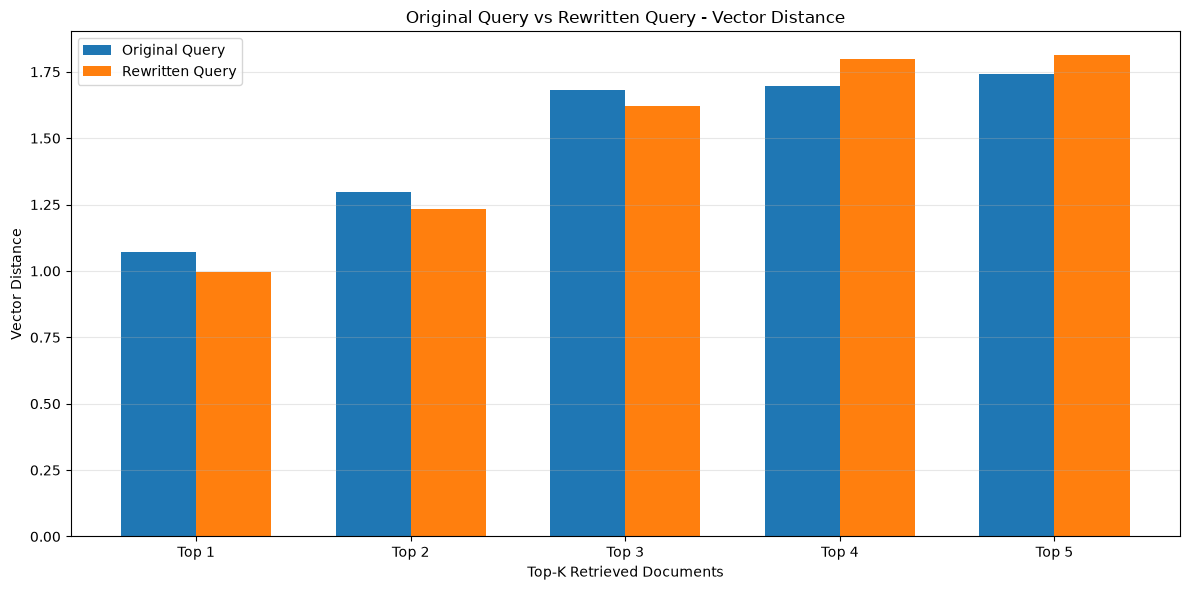

In [187]:
import matplotlib.pyplot as plt
import numpy as np

original_distances = [
    item["distance"] for item in original_results
]

rewritten_distances = [
    item["distance"] for item in retrieved_chunks
]

x = np.arange(1, 6)
width = 0.35

plt.figure(figsize=(12, 6))

plt.bar(
    x - width/2,
    original_distances,
    width,
    label="Original Query"
)

plt.bar(
    x + width/2,
    rewritten_distances,
    width,
    label="Rewritten Query"
)

plt.xlabel("Top-K Retrieved Documents")
plt.ylabel("Vector Distance")

plt.title("Original Query vs Rewritten Query - Vector Distance")

plt.xticks(x, [f"Top {i}" for i in x])
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

Total document vectors: 38
Embedding started...
Embedding completed!
Embedding started...
Embedding completed!


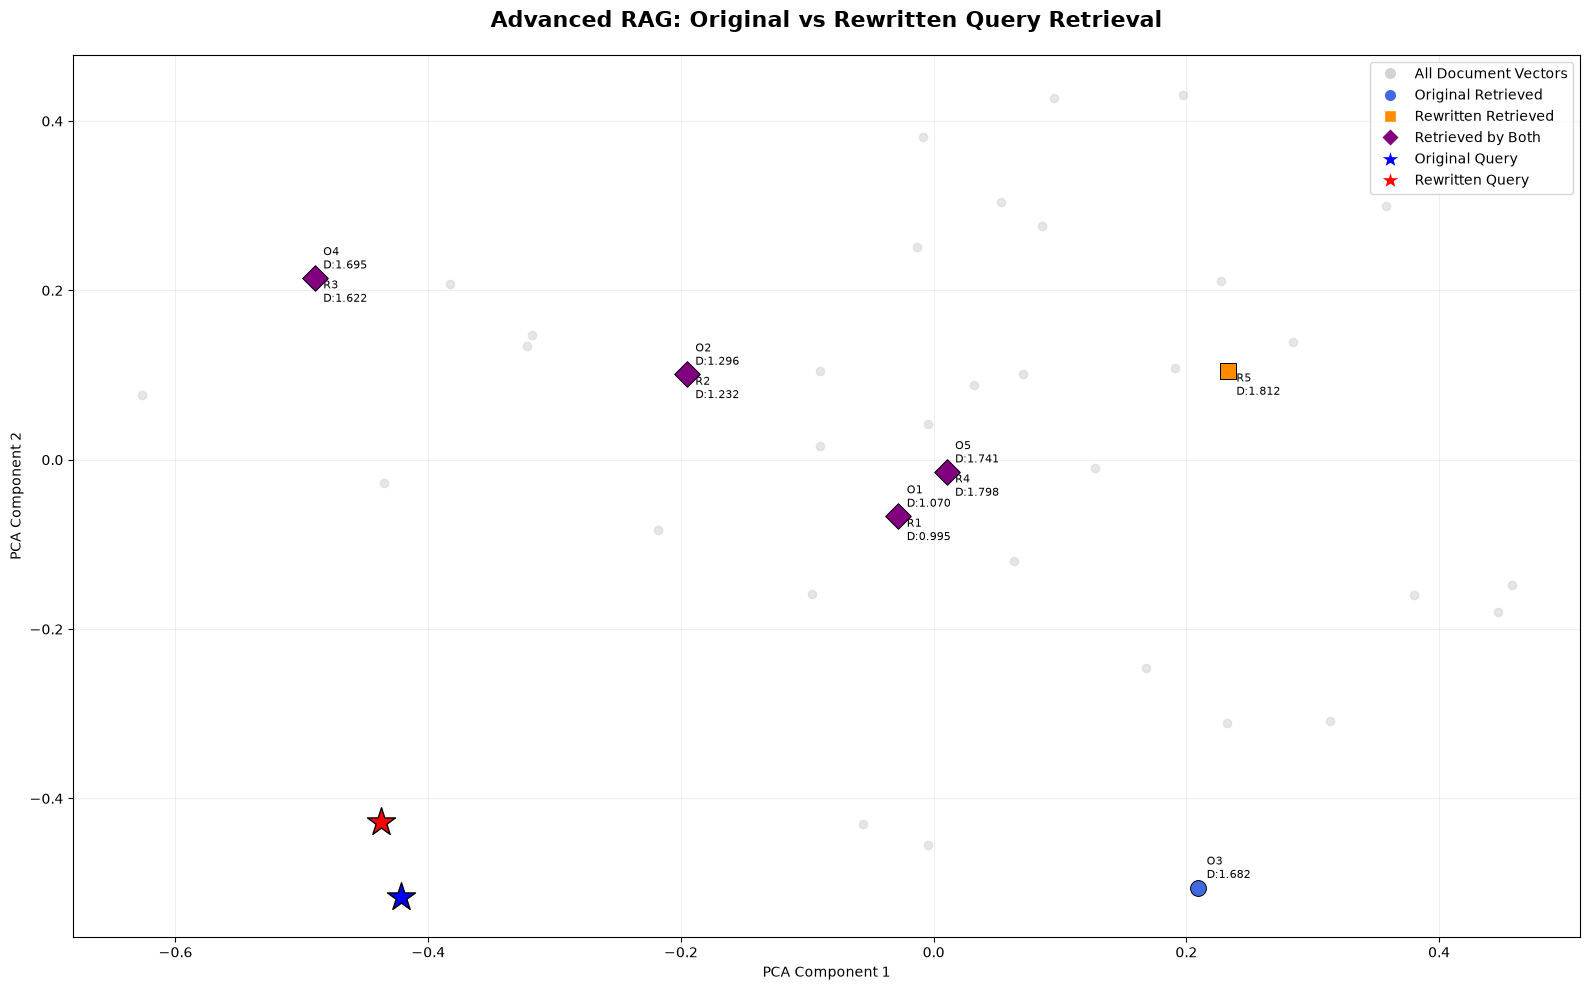

In [189]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA
from matplotlib.lines import Line2D

# ==========================================
# 1. Get ALL document vectors from ChromaDB
# ==========================================

all_data = collection.get(
    include=["embeddings"]
)

document_ids = all_data["ids"]
document_vectors = np.array(all_data["embeddings"])

print("Total document vectors:", len(document_vectors))


# ==========================================
# 2. Generate query embeddings
# ==========================================

original_query_vector = np.array(
    create_embeddings([user_query])[0]
)

rewritten_query_vector = np.array(
    create_embeddings([rewritten_query])[0]
)


# ==========================================
# 3. Prepare retrieved document IDs
# ==========================================

original_ids = {
    item["id"] for item in original_results
}

rewritten_ids = {
    item["id"] for item in retrieved_chunks
}

both_ids = original_ids & rewritten_ids


# ==========================================
# 4. Apply PCA dimensionality reduction
# ==========================================

all_vectors = np.vstack([
    document_vectors,
    original_query_vector,
    rewritten_query_vector
])

pca = PCA(n_components=2)

reduced_vectors = pca.fit_transform(all_vectors)

document_points = reduced_vectors[:len(document_vectors)]

original_query_point = reduced_vectors[-2]
rewritten_query_point = reduced_vectors[-1]


# ==========================================
# 5. Map document IDs to coordinates
# ==========================================

id_to_index = {
    doc_id: index
    for index, doc_id in enumerate(document_ids)
}


# ==========================================
# 6. Create professional visualization
# ==========================================

fig, ax = plt.subplots(figsize=(16, 10))

# All document vectors in background
ax.scatter(
    document_points[:, 0],
    document_points[:, 1],
    color="lightgray",
    alpha=0.55,
    s=35,
    label="All Document Vectors",
    zorder=1
)

# Original query retrieved chunks
for rank, item in enumerate(original_results, start=1):

    idx = id_to_index[item["id"]]
    point = document_points[idx]

    ax.scatter(
        point[0],
        point[1],
        color="royalblue",
        edgecolors="black",
        linewidths=0.7,
        s=130,
        zorder=3
    )

    ax.annotate(
        f"O{rank}\nD:{item['distance']:.3f}",
        (point[0], point[1]),
        xytext=(6, 7),
        textcoords="offset points",
        fontsize=8
    )


# Rewritten query retrieved chunks
for rank, item in enumerate(retrieved_chunks, start=1):

    idx = id_to_index[item["id"]]
    point = document_points[idx]

    if item["id"] not in both_ids:
        ax.scatter(
            point[0],
            point[1],
            color="darkorange",
            edgecolors="black",
            linewidths=0.7,
            s=130,
            marker="s",
            zorder=4
        )

    else:
        # Shared result: both queries retrieved this chunk
        ax.scatter(
            point[0],
            point[1],
            color="purple",
            edgecolors="black",
            linewidths=0.7,
            s=170,
            marker="D",
            zorder=5
        )

    ax.annotate(
        f"R{rank}\nD:{item['distance']:.3f}",
        (point[0], point[1]),
        xytext=(6, -17),
        textcoords="offset points",
        fontsize=8
    )


# Original query position
ax.scatter(
    original_query_point[0],
    original_query_point[1],
    color="blue",
    marker="*",
    s=450,
    edgecolors="black",
    label="Original Query",
    zorder=6
)

# Rewritten query position
ax.scatter(
    rewritten_query_point[0],
    rewritten_query_point[1],
    color="red",
    marker="*",
    s=450,
    edgecolors="black",
    label="Rewritten Query",
    zorder=6
)


# ==========================================
# 7. Legend and styling
# ==========================================

legend_elements = [
    Line2D(
        [0], [0],
        marker="o",
        color="w",
        markerfacecolor="lightgray",
        markersize=9,
        label="All Document Vectors"
    ),
    Line2D(
        [0], [0],
        marker="o",
        color="w",
        markerfacecolor="royalblue",
        markersize=9,
        label="Original Retrieved"
    ),
    Line2D(
        [0], [0],
        marker="s",
        color="w",
        markerfacecolor="darkorange",
        markersize=9,
        label="Rewritten Retrieved"
    ),
    Line2D(
        [0], [0],
        marker="D",
        color="w",
        markerfacecolor="purple",
        markersize=9,
        label="Retrieved by Both"
    ),
    Line2D(
        [0], [0],
        marker="*",
        color="w",
        markerfacecolor="blue",
        markersize=15,
        label="Original Query"
    ),
    Line2D(
        [0], [0],
        marker="*",
        color="w",
        markerfacecolor="red",
        markersize=15,
        label="Rewritten Query"
    )
]

ax.legend(
    handles=legend_elements,
    loc="upper right",
    frameon=True
)

ax.set_title(
    "Advanced RAG: Original vs Rewritten Query Retrieval",
    fontsize=16,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("PCA Component 1")
ax.set_ylabel("PCA Component 2")

ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()